# 🫁 Lung Cancer CT-Scan Classification
### ResNet50 vs ResNet152 vs EfficientNetB0 vs Vision Transformer (ViT)

**Dataset:** IQ-OTH/NCCD Lung Cancer Dataset (CT scan images)
**Classes (3):** Benign cases, Malignant cases, Normal cases

**In this notebook we will train 4 different deep learning models and compare their accuracy:**
1. ResNet50 (Transfer Learning)
2. ResNet152 (Transfer Learning)
3. EfficientNetB0 (Transfer Learning)
4. Vision Transformer / ViT (built from scratch, small version)

Every step is in its own separate cell so it's easy to follow. Run the cells **in order, top to bottom** (or use Run All).


## Step 1: Upload the Dataset


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive (1).zip


## Step 2: Zip File Extract

In [ ]:
import zipfile
import os

zip_path = "archive.zip"
extract_path = "/content/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extract ho gaya!")
print("Extracted folder ke andar ye files/folders hain:")
print(os.listdir(extract_path))

Dataset extract ho gaya!
Extracted folder ke andar ye files/folders hain:
['.config', 'archive.zip', 'The IQ_OTH_NCCD lung cancer dataset', 'archive (1).zip', 'sample_data']


## Step 3: Libraries Import

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Optional Speed Boost

In [ ]:
import tensorflow as tf

# Allow TensorFlow to use GPU memory gradually
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

# Mixed precision is faster on Colab T4 GPUs
if gpus:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    tf.config.optimizer.set_jit(True)  # XLA compilation

print('GPU:', gpus)
print('Mixed precision:', tf.keras.mixed_precision.global_policy())
print('XLA JIT: enabled')


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision: <DTypePolicy "mixed_float16">
XLA JIT: enabled


## Step 4: Locate Train / Validation / Test Folders
Inside the dataset there are `train`, `validation`, `test` folders, each containing 3 class folders (Benign, Malignant, Normal). The code below automatically finds these folders, no matter how deeply nested they are inside the zip.

In [ ]:
def find_folder(root_dir, target_name):
    """root_dir ke andar target_name (jaise 'train') naam ka folder dhoondta hai"""
    for dirpath, dirnames, filenames in os.walk(root_dir):
        for d in dirnames:
            if d.lower() == target_name.lower():
                return os.path.join(dirpath, d)
    return None

TRAIN_DIR = find_folder(extract_path, "train")
VAL_DIR   = find_folder(extract_path, "validation")
TEST_DIR  = find_folder(extract_path, "test")

print("Train folder:", TRAIN_DIR)
print("Validation folder:", VAL_DIR)
print("Test folder:", TEST_DIR)

Train folder: /content/The IQ_OTH_NCCD lung cancer dataset/dataset/train
Validation folder: /content/The IQ_OTH_NCCD lung cancer dataset/dataset/validation
Test folder: /content/The IQ_OTH_NCCD lung cancer dataset/dataset/test


## Step 5: Set Parameters

In [ ]:
IMG_SIZE = 128       # har image ko 128x128 pixels mein resize karein ge
BATCH_SIZE = 32      # ek waqt mein kitni images model ko dikhayen ge
EPOCHS = 30           # har model kitni baar poora dataset dekhega

print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")

Image size: 128x128
Batch size: 32
Epochs: 30


## Step 6: Load the Dataset
`image_dataset_from_directory` is a built-in Keras function that loads images from a folder and automatically assigns labels (the folder name becomes the class name).

In [ ]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=True,
    seed=42
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

# class names dataset object banate hi save kar lete hain
CLASS_NAMES = train_ds_raw.class_names
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

Found 3000 files belonging to 3 classes.
Found 600 files belonging to 3 classes.
Found 600 files belonging to 3 classes.
Classes: ['Bengin cases', 'Malignant cases', 'Normal cases']
Number of classes: 3


In [ ]:
# Performance behtar karne ke liye caching + prefetching
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds_raw.cache().shuffle(1000, seed=42).prefetch(AUTOTUNE)
val_ds   = val_ds_raw.cache().prefetch(AUTOTUNE)
test_ds  = test_ds_raw.cache().prefetch(AUTOTUNE)

## Step 7: View Some Sample Images

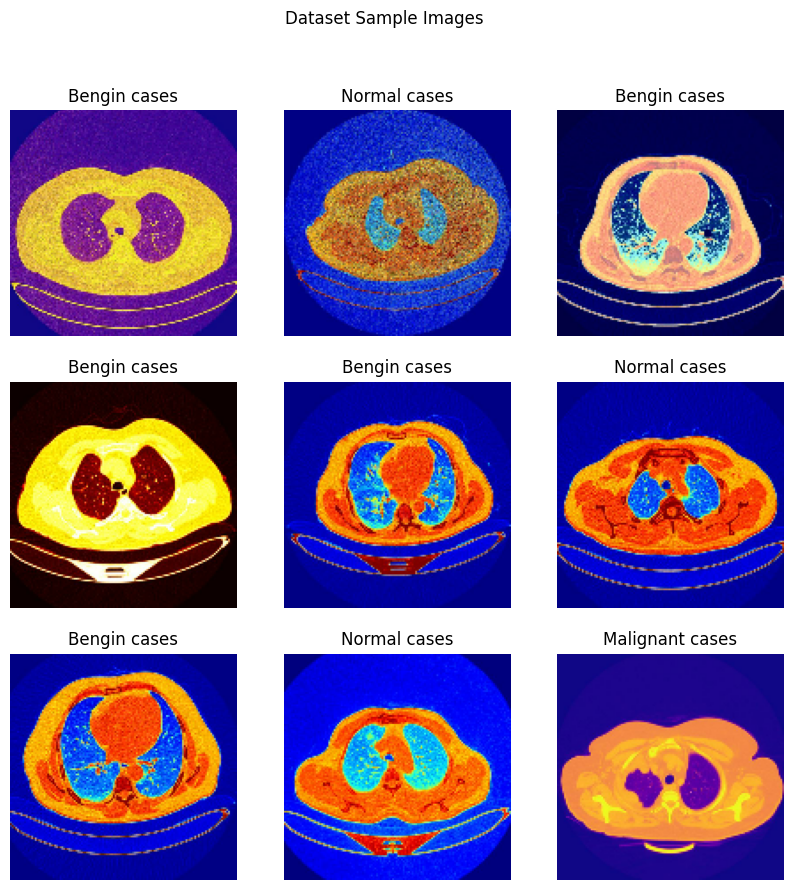

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds_raw.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[labels[i]])
        plt.axis("off")
plt.suptitle("Dataset Sample Images")
plt.show()

## Step 8: Helper Functions
We'll reuse these 2 functions for every model, so let's define them once here:
- `plot_history()` -> plots training/validation accuracy and loss curves
- `evaluate_model()` -> shows test accuracy, a classification report, and a confusion matrix

We also define a small data augmentation layer here, so each model trains on slightly randomized (flipped/rotated/zoomed) images, which helps reduce overfitting.

In [ ]:
def data_augmentation_layer():
    """Chhoti si random augmentation - sirf training ke waqt active hoti hai"""
    return tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ], name="data_augmentation")


def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Train Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend()
    plt.title(f'{model_name} - Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend()
    plt.title(f'{model_name} - Loss')

    plt.show()


def evaluate_model(model, test_ds, model_name):
    """Test set par model ko evaluate karta hai aur report/confusion matrix dikhata hai"""
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    print(f"\n{model_name} -> Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

    y_true = []
    y_pred = []
    for images, labels in test_ds:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(cmap="Blues", ax=ax, colorbar=False)
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return test_acc

## Model 1: ResNet50
ResNet50 is already pretrained on ImageNet (transfer learning). We **freeze** the base model (its weights won't change) and only train our new classification head on top — this makes training fast and works well even on a small dataset.

In [ ]:
def build_transfer_model(base_model_class, preprocess_fn, model_name):
    """ResNet/EfficientNet jaisi pretrained models ke liye common function"""
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation_layer()(inputs)
    x = layers.Lambda(preprocess_fn)(x)   # har model ka apna preprocessing hota hai

    base_model = base_model_class(
        include_top=False,
        weights='imagenet',
        input_tensor=x
    )
    base_model.trainable = False   # pretrained layers freeze

    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name=model_name)
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
resnet50_model = build_transfer_model(
    tf.keras.applications.ResNet50,
    tf.keras.applications.resnet.preprocess_input,
    "ResNet50"
)
resnet50_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 128, 128,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 128, 128,  │          0 │ data_augmentatio… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 134, 134,  │          0 │ lambda[0][0]      │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 64, 64,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 64, 64,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 66, 66,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 32, 32,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 32, 32,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 32, 32,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 32, 32,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 32, 32,    │     16,640 │ conv2_block1_2_r

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
history_resnet50 = resnet50_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 36s 161ms/step - accuracy: 0.5773 - loss: 1.0531 - val_accuracy: 0.6300 - val_loss: 0.8017
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 25s 138ms/step - accuracy: 0.6957 - loss: 0.6209 - val_accuracy: 0.7233 - val_loss: 0.5543
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7277 - loss: 0.5860 - val_accuracy: 0.7200 - val_loss: 0.6079
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7547 - loss: 0.5204 - val_accuracy: 0.7133 - val_loss: 0.7114
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7627 - loss: 0.5090 - val_accuracy: 0.7300 - val_loss: 0.6717
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7867 - loss: 0.4672 - val_accuracy: 0.7417 - val_loss: 0.6162
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7803 - loss: 0.4580 - val_accuracy: 0.7183 - val_loss: 0.5928
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8117 - loss: 0.4214 - val_accuracy: 0.7700

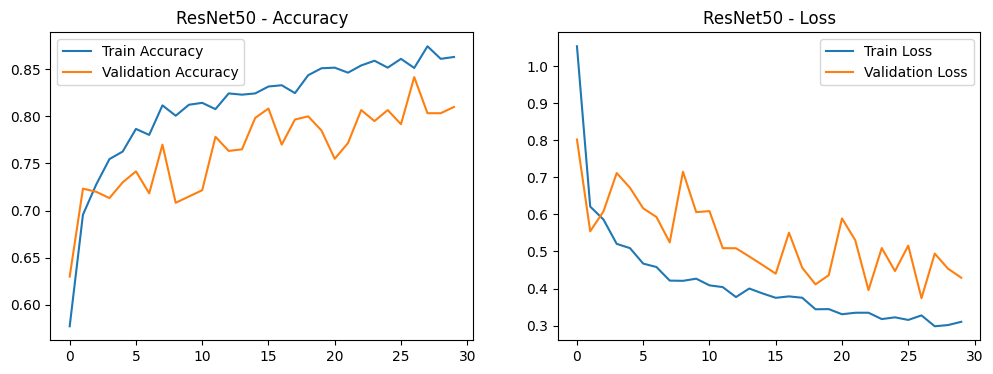


ResNet50 -> Test Loss: 0.4752 | Test Accuracy: 0.8100

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.75      0.80      0.77       200
Malignant cases       0.97      0.86      0.92       200
   Normal cases       0.73      0.77      0.75       200

       accuracy                           0.81       600
      macro avg       0.82      0.81      0.81       600
   weighted avg       0.82      0.81      0.81       600



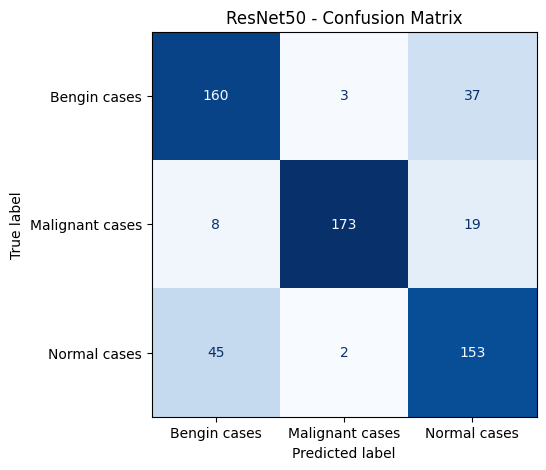

In [ ]:
plot_history(history_resnet50, "ResNet50")
test_acc_resnet50 = evaluate_model(resnet50_model, test_ds, "ResNet50")

## Model 2: ResNet152
Same approach, just a bigger/deeper model (152 layers).

In [ ]:
resnet152_model = build_transfer_model(
    tf.keras.applications.ResNet152,
    tf.keras.applications.resnet.preprocess_input,
    "ResNet152"
)
resnet152_model.summary()

234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "ResNet152"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 128, 128,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 128, 128,  │          0 │ data_augmentatio… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 134, 134,  │          0 │ lambda_1[0][0]    │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 64, 64,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 64, 64,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 66, 66,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 32, 32,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 32, 32,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 32, 32,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 32, 32,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 32, 32,    │     16,640 │ conv2_block1_2_r

 Total params: 58,633,603 (223.67 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 58,370,944 (222.67 MB)

In [ ]:
history_resnet152 = resnet152_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 46s 207ms/step - accuracy: 0.5567 - loss: 1.1472 - val_accuracy: 0.6533 - val_loss: 0.7216
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 16s 91ms/step - accuracy: 0.6823 - loss: 0.6730 - val_accuracy: 0.7017 - val_loss: 0.5962
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7040 - loss: 0.6136 - val_accuracy: 0.7350 - val_loss: 0.5591
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7317 - loss: 0.5636 - val_accuracy: 0.6833 - val_loss: 0.6194
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7617 - loss: 0.5220 - val_accuracy: 0.6867 - val_loss: 0.5980
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7450 - loss: 0.5387 - val_accuracy: 0.7300 - val_loss: 0.5171
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7580 - loss: 0.5136 - val_accuracy: 0.7517 - val_loss: 0.4977
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.7807 - loss: 0.4702 - val_accuracy: 0.7533 

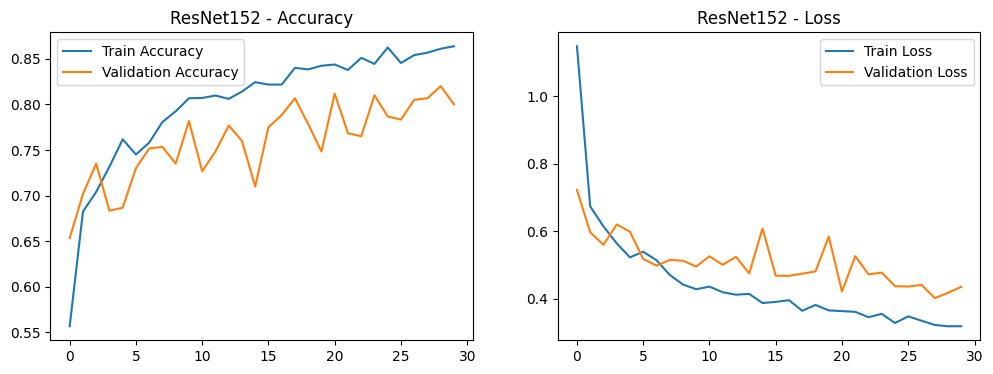


ResNet152 -> Test Loss: 0.4529 | Test Accuracy: 0.8250

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.76      0.76      0.76       200
Malignant cases       0.98      0.90      0.93       200
   Normal cases       0.76      0.82      0.79       200

       accuracy                           0.82       600
      macro avg       0.83      0.83      0.83       600
   weighted avg       0.83      0.82      0.83       600



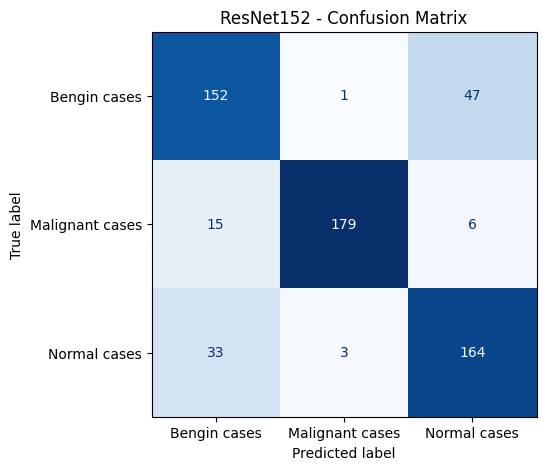

In [ ]:
plot_history(history_resnet152, "ResNet152")
test_acc_resnet152 = evaluate_model(resnet152_model, test_ds, "ResNet152")

## Model 3: EfficientNetB0
EfficientNetB0 is a small but very efficient pretrained model (a good balance between accuracy and speed).

In [ ]:
efficientnet_model = build_transfer_model(
    tf.keras.applications.EfficientNetB0,
    tf.keras.applications.efficientnet.preprocess_input,
    "EfficientNetB0"
)
efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 128, 128,  │          0 │ input_layer_4[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 128, 128,  │          0 │ data_augmentatio… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ lambda_2[0][0]    │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 128, 128,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 128, 128,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 129, 129,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 64, 64,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 64, 64,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 64, 64,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 64, 64,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 94s 431ms/step - accuracy: 0.6680 - loss: 0.6895 - val_accuracy: 0.5983 - val_loss: 0.8338
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 65s 703ms/step - accuracy: 0.7277 - loss: 0.5630 - val_accuracy: 0.6850 - val_loss: 0.6811
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7697 - loss: 0.5017 - val_accuracy: 0.7183 - val_loss: 0.6194
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7893 - loss: 0.4673 - val_accuracy: 0.7017 - val_loss: 0.6683
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8063 - loss: 0.4395 - val_accuracy: 0.6817 - val_loss: 0.7291
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8187 - loss: 0.4101 - val_accuracy: 0.7167 - val_loss: 0.6438
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8343 - loss: 0.3917 - val_accuracy: 0.7417 - val_loss: 0.6624
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8377 - loss: 0.3775 - val_accuracy: 0.7367

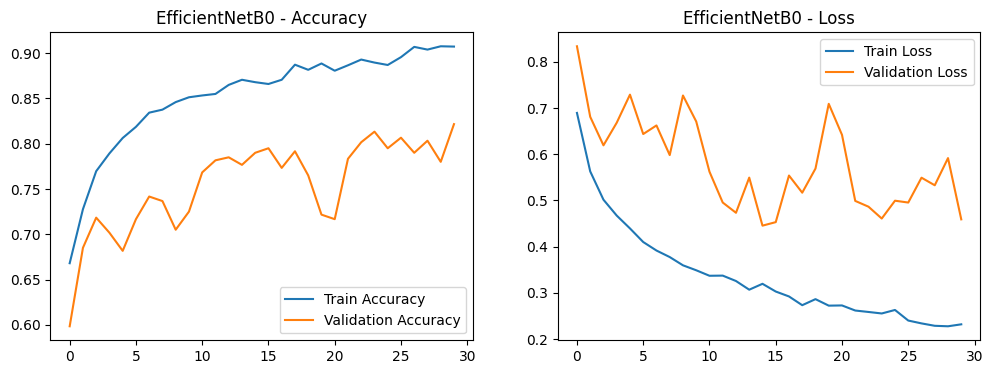


EfficientNetB0 -> Test Loss: 0.3991 | Test Accuracy: 0.8400

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.77      0.88      0.82       200
Malignant cases       1.00      0.83      0.91       200
   Normal cases       0.79      0.81      0.80       200

       accuracy                           0.84       600
      macro avg       0.85      0.84      0.84       600
   weighted avg       0.85      0.84      0.84       600



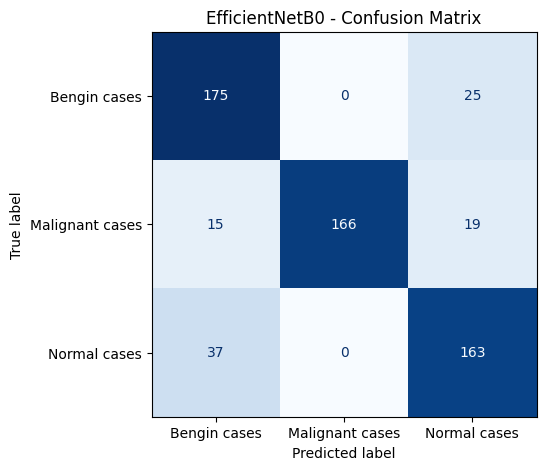

In [ ]:
plot_history(history_efficientnet, "EfficientNetB0")
test_acc_efficientnet = evaluate_model(efficientnet_model, test_ds, "EfficientNetB0")

## Model 4: VGG16
VGG16 is one of the earliest and simplest deep CNN architectures, made of small 3x3 convolution blocks stacked on top of each other. It's a good classic baseline to compare against the more modern models above.

In [ ]:
vgg16_model = build_transfer_model(
    tf.keras.applications.VGG16,
    tf.keras.applications.vgg16.preprocess_input,
    "VGG16"
)
vgg16_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_3 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
history_vgg16 = vgg16_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.5233 - loss: 2.8726 - val_accuracy: 0.6583 - val_loss: 0.9129
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 99ms/step - accuracy: 0.6587 - loss: 0.8210 - val_accuracy: 0.6883 - val_loss: 0.6208
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.7173 - loss: 0.6294 - val_accuracy: 0.7400 - val_loss: 0.5704
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.7397 - loss: 0.5945 - val_accuracy: 0.7850 - val_loss: 0.5102
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.7570 - loss: 0.5355 - val_accuracy: 0.7800 - val_loss: 0.4890
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.7787 - loss: 0.5020 - val_accuracy: 0.7433 - val_loss: 0.6048
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8000 - loss: 0.4561 - val_accuracy: 0.7950 - val_loss: 0.5217
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8043 - loss: 0.4526 - val_accuracy: 0.7783 - 

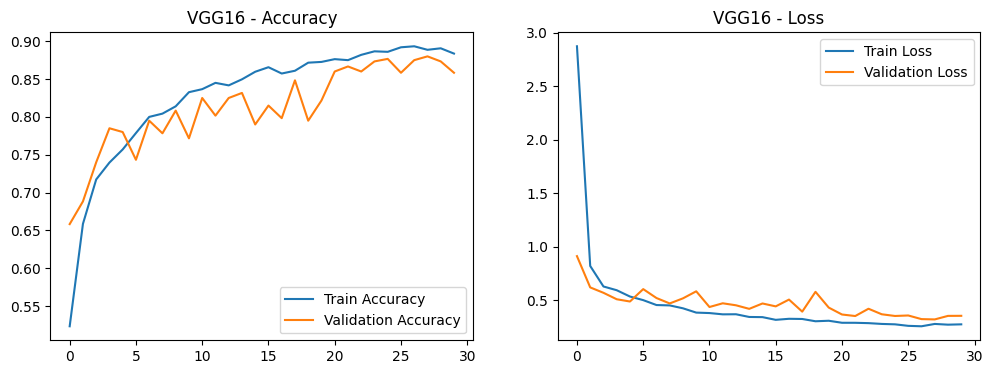


VGG16 -> Test Loss: 0.3273 | Test Accuracy: 0.8667

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.83      0.85      0.84       200
Malignant cases       0.98      0.88      0.93       200
   Normal cases       0.80      0.86      0.83       200

       accuracy                           0.87       600
      macro avg       0.87      0.87      0.87       600
   weighted avg       0.87      0.87      0.87       600



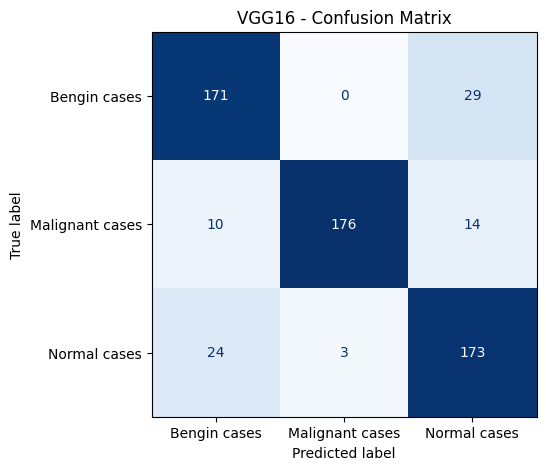

In [ ]:
plot_history(history_vgg16, "VGG16")
test_acc_vgg16 = evaluate_model(vgg16_model, test_ds, "VGG16")

## Model 5: InceptionV3
InceptionV3 uses "inception blocks" that look at the image at multiple filter sizes (1x1, 3x3, 5x5) at the same time, then combine the results. This lets it capture both small and large patterns efficiently.

In [ ]:
inception_model = build_transfer_model(
    tf.keras.applications.InceptionV3,
    tf.keras.applications.inception_v3.preprocess_input,
    "InceptionV3"
)
inception_model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "InceptionV3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 128, 128,  │          0 │ input_layer_8[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_4 (Lambda)   │ (None, 128, 128,  │          0 │ data_augmentatio… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 63, 63,    │        864 │ lambda_4[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 63, 63,    │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 63, 63,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 61, 61,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 61, 61,    │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 61, 61,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 61, 61,    │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 61, 61,    │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 61, 61,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 30, 30,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 30, 30,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 30,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 30, 30,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 28, 28,    │    138,240 │ activation_3[0][

 Total params: 22,065,443 (84.17 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
history_inception = inception_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 34s 148ms/step - accuracy: 0.5257 - loss: 1.4323 - val_accuracy: 0.6067 - val_loss: 0.7460
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 22s 234ms/step - accuracy: 0.6297 - loss: 0.7384 - val_accuracy: 0.6317 - val_loss: 0.6874
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6527 - loss: 0.6902 - val_accuracy: 0.6617 - val_loss: 0.6758
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6803 - loss: 0.6652 - val_accuracy: 0.6967 - val_loss: 0.6435
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6940 - loss: 0.6260 - val_accuracy: 0.6583 - val_loss: 0.6884
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6847 - loss: 0.6503 - val_accuracy: 0.6983 - val_loss: 0.5831
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7047 - loss: 0.6128 - val_accuracy: 0.6550 - val_loss: 0.6262
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7027 - loss: 0.6082 - val_accuracy: 0.7017

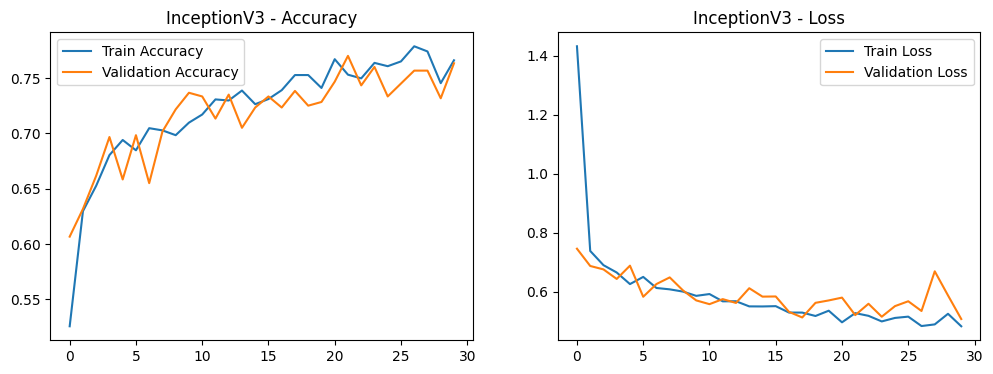


InceptionV3 -> Test Loss: 0.4843 | Test Accuracy: 0.7700

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.75      0.65      0.69       200
Malignant cases       0.95      0.86      0.90       200
   Normal cases       0.65      0.81      0.72       200

       accuracy                           0.77       600
      macro avg       0.78      0.77      0.77       600
   weighted avg       0.78      0.77      0.77       600



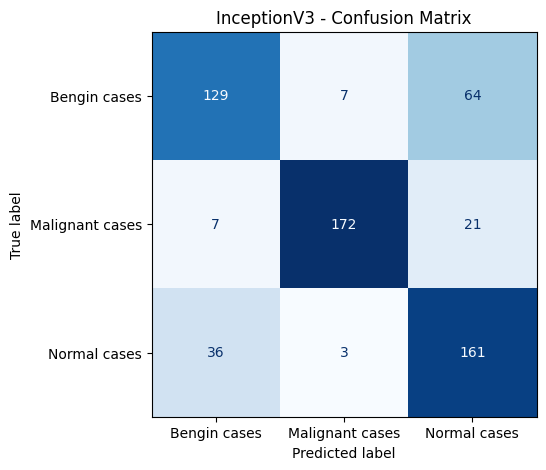

In [ ]:
plot_history(history_inception, "InceptionV3")
test_acc_inception = evaluate_model(inception_model, test_ds, "InceptionV3")

## Model 6: MobileNetV2
MobileNetV2 is a lightweight CNN designed to run fast with very few parameters (originally built for mobile devices). It's a good example of how a small, efficient model compares to the bigger ones above.

In [ ]:
mobilenet_model = build_transfer_model(
    tf.keras.applications.MobileNetV2,
    tf.keras.applications.mobilenet_v2.preprocess_input,
    "MobileNetV2"
)
mobilenet_model.summary()

/tmp/ipykernel_1048/1347990731.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = base_model_class(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 128, 128,  │          0 │ input_layer_10[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_5 (Lambda)   │ (None, 128, 128,  │          0 │ data_augmentatio… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ lambda_5[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 56s 262ms/step - accuracy: 0.6207 - loss: 0.9232 - val_accuracy: 0.6850 - val_loss: 0.6749
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 39s 424ms/step - accuracy: 0.7170 - loss: 0.5861 - val_accuracy: 0.6600 - val_loss: 0.6894
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7563 - loss: 0.5336 - val_accuracy: 0.7083 - val_loss: 0.6177
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7820 - loss: 0.4839 - val_accuracy: 0.6983 - val_loss: 0.7103
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7893 - loss: 0.4642 - val_accuracy: 0.7467 - val_loss: 0.5501
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8047 - loss: 0.4430 - val_accuracy: 0.7583 - val_loss: 0.5364
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7990 - loss: 0.4326 - val_accuracy: 0.7600 - val_loss: 0.5140
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8187 - loss: 0.4073 - val_accuracy: 0.7533

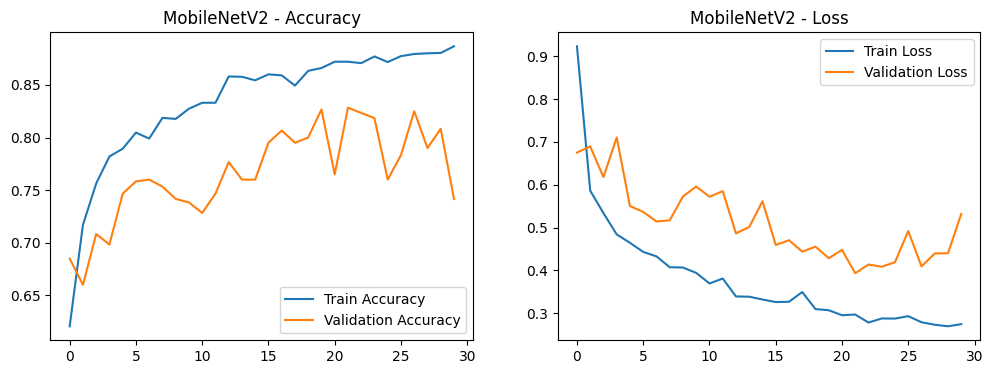


MobileNetV2 -> Test Loss: 0.5509 | Test Accuracy: 0.7267

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.83      0.45      0.58       200
Malignant cases       0.98      0.81      0.88       200
   Normal cases       0.57      0.93      0.70       200

       accuracy                           0.73       600
      macro avg       0.79      0.73      0.72       600
   weighted avg       0.79      0.73      0.72       600



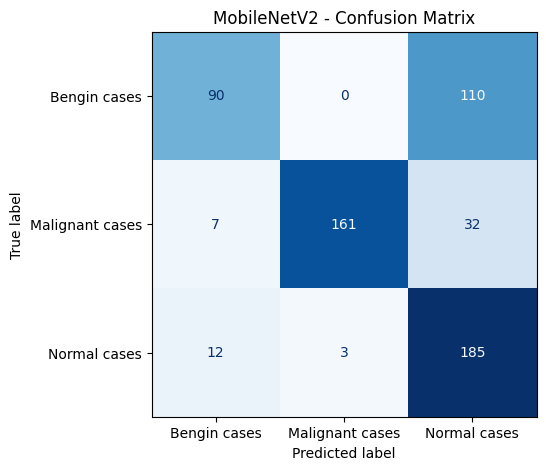

In [ ]:
plot_history(history_mobilenet, "MobileNetV2")
test_acc_mobilenet = evaluate_model(mobilenet_model, test_ds, "MobileNetV2")

## Model 7: Vision Transformer (ViT)
This is different from the previous 3 CNN models — it's a **Transformer** architecture (the same basic idea used by models like ChatGPT for text, applied here to images).

**The basic idea of ViT (in simple terms):**
1. Split the image into small patches — like puzzle pieces
2. Convert each patch into a number-vector (embedding)
3. Apply Transformer layers (Self-Attention) — each patch is compared with every other patch
4. Finally, combine the information from all patches to classify the image

We're building this model **from scratch (without pretrained weights)**, so it's normal for it to be less accurate than the other 3 models — transformers usually need a lot more data/epochs to learn well on a small dataset.

In [ ]:
# ViT ke parameters
PATCH_SIZE = 16
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2
PROJECTION_DIM = 64
NUM_HEADS = 4
TRANSFORMER_LAYERS = 4
MLP_HEAD_UNITS = [128, 64]

print("Total patches per image:", NUM_PATCHES)

Total patches per image: 64


In [ ]:
class Patches(layers.Layer):
    """Image ko chhote-chhote patches mein todne wali layer"""
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches


class PatchEncoder(layers.Layer):
    """Har patch ko ek vector mein encode karta hai + position info add karta hai"""
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )

    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        encoded = self.projection(patch) + self.position_embedding(positions)
        return encoded

In [ ]:
def build_vit_model():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation_layer()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    # Step 1: image ko patches mein todo aur encode karo
    patches = Patches(PATCH_SIZE)(x)
    encoded_patches = PatchEncoder(NUM_PATCHES, PROJECTION_DIM)(patches)

    # Step 2: Transformer blocks (Self-Attention + MLP)
    for _ in range(TRANSFORMER_LAYERS):
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        attention_output = layers.MultiHeadAttention(
            num_heads=NUM_HEADS, key_dim=PROJECTION_DIM, dropout=0.1
        )(x1, x1)
        x2 = layers.Add()([attention_output, encoded_patches])

        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        x3 = layers.Dense(PROJECTION_DIM * 2, activation="relu")(x3)
        x3 = layers.Dropout(0.1)(x3)
        x3 = layers.Dense(PROJECTION_DIM)(x3)
        encoded_patches = layers.Add()([x3, x2])

    # Step 3: sab patches ki info combine karo aur classify karo
    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.GlobalAveragePooling1D()(representation)
    representation = layers.Dropout(0.3)(representation)

    features = representation
    for units in MLP_HEAD_UNITS:
        features = layers.Dense(units, activation="relu")(features)
        features = layers.Dropout(0.3)(features)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(features)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Vision_Transformer")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


vit_model = build_vit_model()
vit_model.summary()

Model: "Vision_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 128, 128,  │          0 │ input_layer_12[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 128, 128,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 768) │          0 │ rescaling_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 64, 64)    │     53,312 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 64)    │        128 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64)    │          0 │ multi_head_atten… │
│                     │                   │            │ patch_encoder[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64, 128)   │          0 │ dense_13[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 64, 64)    │      8,256 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64)    │          0 │ dense_14[0][0],   │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 64)    │          0 │ multi_head_atten… │
│                     │                   │            │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 403,011 (1.54 MB)

 Trainable params: 403,011 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 33s 57ms/step - accuracy: 0.3260 - loss: 1.0989 - val_accuracy: 0.3333 - val_loss: 1.0985
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 151ms/step - accuracy: 0.3187 - loss: 1.0997 - val_accuracy: 0.3333 - val_loss: 1.0985
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.3323 - loss: 1.0985 - val_accuracy: 0.3333 - val_loss: 1.0984
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3343 - loss: 1.0981 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3350 - loss: 1.0993 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3370 - loss: 1.0984 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3350 - loss: 1.0983 - val_accuracy: 0.3383 - val_loss: 1.0984
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.3307 - loss: 1.0986 - val_accuracy: 0.3817 

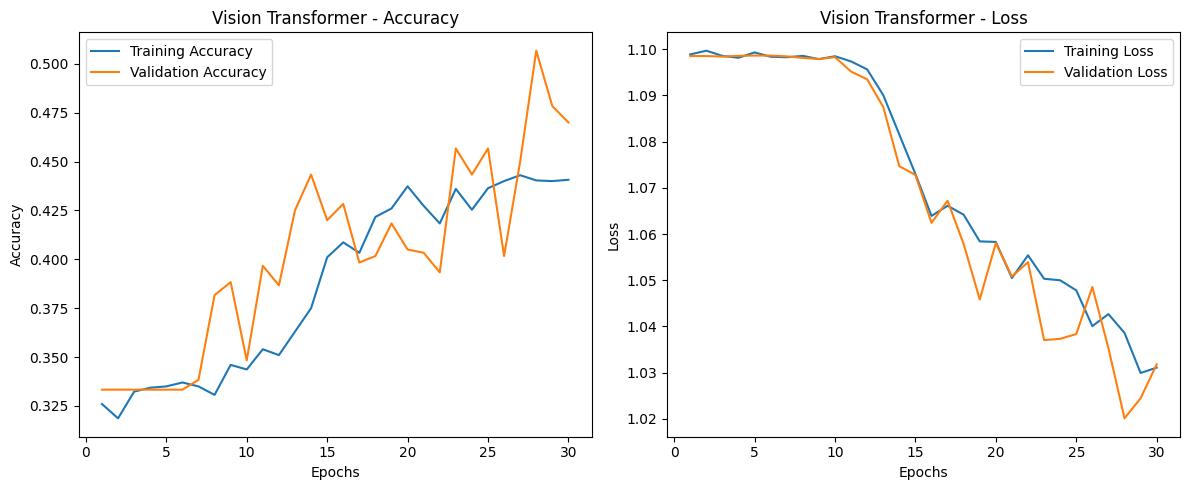


Vision Transformer Results
--------------------------
Test Loss: 1.0545
Test Accuracy: 0.4500

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.40      0.49      0.44       200
Malignant cases       0.61      0.36      0.46       200
   Normal cases       0.42      0.49      0.45       200

       accuracy                           0.45       600
      macro avg       0.48      0.45      0.45       600
   weighted avg       0.48      0.45      0.45       600


Confusion Matrix:
[[98 30 72]
 [60 73 67]
 [85 16 99]]


<Figure size 700x600 with 0 Axes>

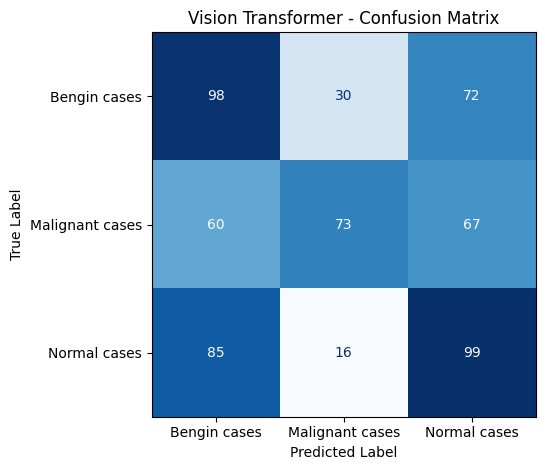

In [ ]:
# ================================
# Vision Transformer - Training & Evaluation
# ================================

# Use a smaller learning rate for stable training
vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the Vision Transformer
history_vit = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    verbose=1
)

# ================================
# Training and Validation Graphs
# ================================

acc = history_vit.history["accuracy"]
val_acc = history_vit.history["val_accuracy"]
loss = history_vit.history["loss"]
val_loss = history_vit.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Vision Transformer - Accuracy")
plt.legend()

# Loss Graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Vision Transformer - Loss")
plt.legend()

plt.tight_layout()
plt.show()


# ================================
# Test Evaluation
# ================================

test_loss, test_acc = vit_model.evaluate(test_ds, verbose=0)

print("\nVision Transformer Results")
print("--------------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# ================================
# Predictions
# ================================

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = vit_model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)


# ================================
# Classification Report
# ================================

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


# ================================
# Confusion Matrix
# ================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Vision Transformer - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Save accuracy for final model comparison
test_acc_vit = test_acc

## Final Step: Comparing All Models

Test Accuracy Comparison:
  ResNet50            : 0.8100
  ResNet152           : 0.8250
  EfficientNetB0      : 0.8400
  VGG16               : 0.8667
  InceptionV3         : 0.7700
  MobileNetV2         : 0.7267
  Vision Transformer  : 0.4500


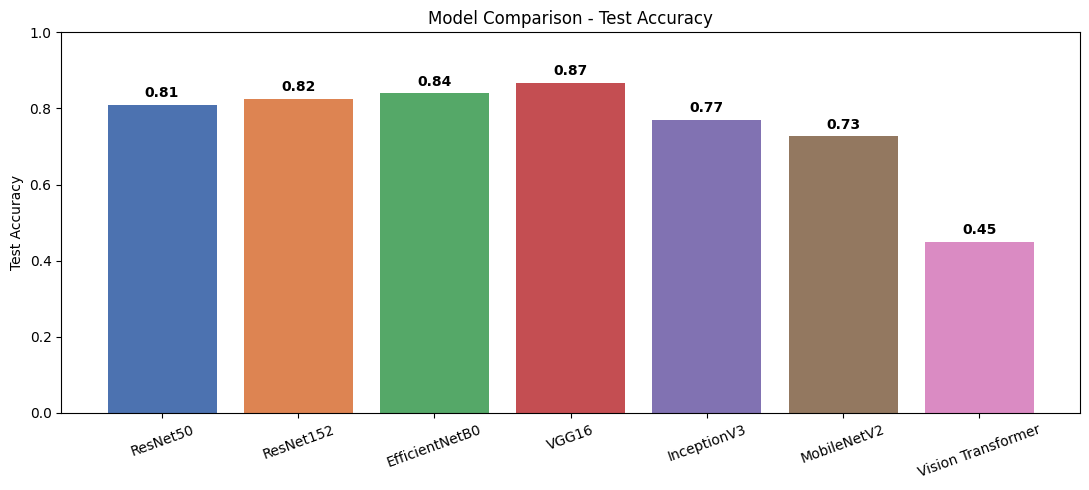


Best performing model: VGG16 (Accuracy: 0.8667)


In [ ]:
results = {
    "ResNet50": test_acc_resnet50,
    "ResNet152": test_acc_resnet152,
    "EfficientNetB0": test_acc_efficientnet,
    "VGG16": test_acc_vgg16,
    "InceptionV3": test_acc_inception,
    "MobileNetV2": test_acc_mobilenet,
    "Vision Transformer": test_acc_vit,
}

print("Test Accuracy Comparison:")
for name, acc in results.items():
    print(f"  {name:20s}: {acc:.4f}")

plt.figure(figsize=(11, 5))
bars = plt.bar(results.keys(), results.values(),
               color=['#4C72B0', '#DD8452', '#55A868', '#C44E52',
                      '#8172B2', '#937860', '#DA8BC3'])
plt.ylabel("Test Accuracy")
plt.title("Model Comparison - Test Accuracy")
plt.ylim(0, 1)
for bar, acc in zip(bars, results.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, acc + 0.02, f"{acc:.2f}",
             ha='center', fontweight='bold')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

best_model = max(results, key=results.get)
print(f"\nBest performing model: {best_model} (Accuracy: {results[best_model]:.4f})")

## Conclusion
- **ResNet50, ResNet152, EfficientNetB0, VGG16, InceptionV3, MobileNetV2** — all six are pretrained (ImageNet) CNNs trained here with transfer learning, so they were able to learn quickly even on this relatively small dataset.
- **Vision Transformer (ViT)** — this was trained from scratch (no pretrained weights), so it's normal for it to score lower than the CNNs above unless the dataset is much larger or the ViT is pretrained too.
- Comparing all 7 models together shows the trade-off between model size, architecture, and accuracy on this dataset — heavier models like ResNet152 or InceptionV3 aren't always better than lighter ones like MobileNetV2 or EfficientNetB0.

